# Buscador de comercios sin web · Capstone SIC (prueba de concepto)

**Pregunta de negocio:** ¿qué comercios de Concordia y Paraná (Entre Ríos) no tienen web propia y a cuáles conviene ofrecerles una primero?

**Cliente:** una agencia o freelancer que vende sitios web a comercios locales.
**Fuente:** Google Maps, extraído con Apify (`kaix/google-maps-places-scraper`), 12 rubros × 2 ciudades.

| Sección | Qué responde |
|---|---|
| 0 | Configuración y carga de datos |
| 1 | ETL: de la respuesta de Google Maps a una tabla limpia (embudo + validaciones) |
| 2 | EDA: distribuciones, frecuencias y correlaciones |
| 3 | Inferencia: ¿la falta de web depende del rubro / ciudad? ¿los que no tienen web tienen menos movimiento? |
| 4 | Selección de features (5 lineales + 5 no lineales) |
| 5 | Modelo: probabilidad de tener web propia y puntaje de prioridad para los leads |
| 6 | Métrica de negocio y KPI |
| 7 | Exportar resultados |

Cada función del ETL documenta **Input / Output / Proceso** para traducirla a un módulo de Make, un nodo de n8n o al Actor de Apify del repo (`actor_apify/src/etl.py`).

## 0. Configuración

In [1]:
import json, os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEMILLA = 42
ALFA = 0.05

# --- Rutas: en Colab se monta Drive; en local se usan las carpetas del repo
RUTA_DRIVE = "/content/drive/MyDrive/Capstone/comercios_sin_web/datos"      # <- CAMBIAR si la carpeta es otra
SALIDA_DRIVE = "/content/drive/MyDrive/Capstone/comercios_sin_web/salida"
RUTA_LOCAL, SALIDA_LOCAL = "../../data/raw", "../../data/processed"
ARCHIVOS = {"Concordia": "maps_concordia.json", "Paraná": "maps_parana.json"}
try:
    from google.colab import drive
    drive.mount("/content/drive")
    EN_COLAB = True
except ImportError:
    EN_COLAB = False
BASE = RUTA_DRIVE if EN_COLAB else RUTA_LOCAL
DIR_SALIDA = SALIDA_DRIVE if EN_COLAB else SALIDA_LOCAL
faltan = [f for f in ARCHIVOS.values() if not os.path.exists(os.path.join(BASE, f))]
assert not faltan, f"No se encuentran {faltan} en {BASE}"
print("Entorno:", "Colab + Drive" if EN_COLAB else "local", "| datos:", BASE)

Entorno: local | datos: ../../data/raw


## 1. ETL
Las funciones son las mismas que usa el Actor de Apify (`actor_apify/src/etl.py`), copiadas acá para que el notebook sea autocontenido.

**Reglas de negocio documentadas**
- *Web propia* = el campo `website` de Google Maps apunta a un dominio propio. Si apunta a Instagram, Facebook, WhatsApp o Linktree es **solo redes**; si apunta a PedidosYa, Mercado Libre, Tiendanube o sitios gratuitos de Google es **plataforma de terceros**. Ninguno de los dos cuenta como web propia: los tres casos son *leads*.
- *Lead caliente* = sin web propia, con teléfono, rating ≥ 4 y al menos 10 reseñas (negocio activo y con reputación que cuidar).
- Se descartan lugares fuera de Argentina (la búsqueda desde Concordia alcanza Salto, Uruguay), cerrados y duplicados.

In [2]:
"""
ETL del buscador de comercios sin web (Google Maps -> tabla de leads).

Cada función documenta Input, Output y Proceso para poder traducirla
1 a 1 a un módulo de Make / nodo de n8n, o correrla dentro del Actor de Apify.
Solo usa la librería estándar + pandas/numpy.
"""

import re
import unicodedata
from urllib.parse import urlparse

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# Reglas de negocio (constantes documentadas)
# ---------------------------------------------------------------------------
DOMINIOS_REDES = (
    "instagram.com", "facebook.com", "fb.com", "fb.me", "wa.me", "whatsapp.com",
    "linktr.ee", "tiktok.com", "twitter.com", "x.com", "youtube.com", "linkedin.com",
    "beacons.ai", "taplink.cc", "bio.link",
)
# Plataformas de tienda/reserva de terceros: el comercio tiene presencia, pero no web propia.
DOMINIOS_TERCEROS = (
    "pedidosya.com", "rappi.com", "mercadolibre.com", "mercadoshops.com",
    "tiendanube.com", "mitiendanube.com", "empretienda.com", "google.com", "business.site", "negocio.site",
    "wixsite.com", "blogspot.com", "agendapro.com", "reservio.com",
)
CIUDADES = {"concordia": 1, "parana": 2, "gualeguaychu": 3, "concepcion del uruguay": 4}
RUBROS = {
    "peluqueria": 1, "ferreteria": 2, "almacen": 3, "taller mecanico": 4, "panaderia": 5,
    "veterinaria": 6, "gimnasio": 7, "carniceria": 8, "restaurante": 9, "tienda de ropa": 10,
    "verduleria": 11, "farmacia": 12,
}
# Lead "caliente": sin web propia, abierto, con teléfono, buena reputación y movimiento.
LEAD_MIN_RATING = 4.0
LEAD_MIN_RESENAS = 10


def sin_acentos(texto: str) -> str:
    """Input: str. Output: str en minúsculas sin tildes. Proceso: normaliza NFKD."""
    t = unicodedata.normalize("NFKD", str(texto or ""))
    return "".join(c for c in t if not unicodedata.combining(c)).lower().strip()


# ---------------------------------------------------------------------------
# E - Extract
# ---------------------------------------------------------------------------
def extraer(registros: list[dict], ciudad_busqueda: str) -> pd.DataFrame:
    """
    Input: lista de dicts tal como los devuelve el Actor de Google Maps + ciudad buscada.
    Output: DataFrame crudo con las columnas que usa el pipeline (una fila por lugar).
    Proceso: aplana los campos anidados que interesan y agrega la ciudad de la búsqueda.
    """
    filas = []
    for r in registros:
        filas.append({
            "place_id": r.get("placeId"),
            "nombre": r.get("title"),
            "rubro_busqueda": r.get("matchedQuery"),
            "categoria_maps": r.get("primaryTypeDisplayName"),
            "ciudad_busqueda": ciudad_busqueda,
            "ciudad_maps": r.get("city"),
            "pais": r.get("countryCode"),
            "direccion": r.get("formattedAddress"),
            "latitud": r.get("latitude"),
            "longitud": r.get("longitude"),
            "rating": r.get("rating"),
            "n_resenas": r.get("reviewCount"),
            "n_fotos": r.get("imagesCount"),
            "web": r.get("website"),
            "telefono": r.get("phone"),
            "perfil_reclamado": r.get("isClaimed"),
            "estado": r.get("businessStatus"),
            "horarios": r.get("hours"),
            "url_maps": r.get("googleMapsUri"),
        })
    return pd.DataFrame(filas)


# ---------------------------------------------------------------------------
# T - Transform
# ---------------------------------------------------------------------------
def clasificar_presencia(url: str | None) -> str:
    """
    Input: URL del campo 'website' de Google Maps (o None).
    Output: 'web_propia' | 'solo_redes' | 'plataforma_terceros' | 'sin_web'.
    Proceso: mira el dominio; Instagram/Facebook/WhatsApp/Linktree cuentan como redes,
             tiendas y sitios gratuitos de terceros no cuentan como web propia.
    """
    if url is None or (isinstance(url, float) and np.isnan(url)) or not str(url).strip():
        return "sin_web"
    u = str(url).strip()
    if not u.startswith("http"):
        u = "http://" + u
    dominio = (urlparse(u).netloc or "").lower().removeprefix("www.")
    partes = dominio.split(".")

    def coincide(d: str) -> bool:
        # 'pedidosya.com' coincide con 'pedidosya.com.ar' y con 'www.pedidosya.com'
        base = d.split(".")[0]
        return dominio == d or dominio.endswith("." + d) or base in partes[:-1]

    if any(coincide(d) for d in DOMINIOS_REDES):
        return "solo_redes"
    if any(coincide(d) for d in DOMINIOS_TERCEROS):
        return "plataforma_terceros"
    return "web_propia"


_RX_FRANJA = re.compile(
    r"(\d{1,2})(?::(\d{2}))?\s*(a\.?\s?m\.?|p\.?\s?m\.?)?\s*[-–]\s*(\d{1,2})(?::(\d{2}))?\s*(a\.?\s?m\.?|p\.?\s?m\.?)?",
    re.I,
)


def _a_hora(h: str, m: str | None, sufijo: str | None, sufijo_fin: str | None) -> float:
    hora = int(h) % 12 if (sufijo or sufijo_fin) else int(h)
    suf = (sufijo or sufijo_fin or "").lower().replace(" ", "").replace(".", "")
    if suf == "pm":
        hora += 12
    return hora + (int(m) / 60 if m else 0)


def horas_semanales(horarios) -> tuple[float, float]:
    """
    Input: lista [{'day': 'lunes', 'hours': '8 a.m.-12 p.m., 4-8 p.m.'}, ...] o None.
    Output: (horas abiertas por semana, días abiertos por semana); (nan, nan) si no hay dato.
    Proceso: parsea cada franja horaria; 'Abierto las 24 horas' = 24 h; 'Cerrado' = 0.
    """
    if not isinstance(horarios, list) or not horarios:
        return (np.nan, np.nan)
    total, dias = 0.0, 0
    for d in horarios:
        txt = sin_acentos(d.get("hours", ""))
        if "cerrado" in txt or "closed" in txt:
            continue
        if "24 horas" in txt or "24 hours" in txt:
            total += 24
            dias += 1
            continue
        horas_dia = 0.0
        for m in _RX_FRANJA.finditer(txt):
            h1, m1, s1, h2, m2, s2 = m.groups()
            # si solo el fin tiene sufijo (ej. '4-8 p.m.'), el inicio hereda el sufijo
            ini = _a_hora(h1, m1, s1 or s2, None)
            fin = _a_hora(h2, m2, s2, None)
            if fin <= ini:
                fin += 12 if fin + 12 > ini else 24
            horas_dia += min(fin - ini, 24)
        if horas_dia > 0:
            total += min(horas_dia, 24)
            dias += 1
    return (round(total, 1), float(dias))


def abre_domingo(horarios) -> float:
    """
    Input: lista de horarios por día (o None).
    Output: 1.0 si atiende el domingo, 0.0 si no, nan si no hay horarios cargados.
    Proceso: busca el día 'domingo' y mira si dice 'Cerrado'.
    """
    if not isinstance(horarios, list) or not horarios:
        return np.nan
    for d in horarios:
        if sin_acentos(d.get("day", "")) in ("domingo", "sunday"):
            return 0.0 if "cerrado" in sin_acentos(d.get("hours", "")) else 1.0
    return 0.0


def transformar(crudo: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Input: DataFrame crudo de extraer() (puede venir de varias corridas/ciudades).
    Output: (limpio, descartes). limpio = una fila por comercio con columnas derivadas;
            descartes = filas eliminadas con el motivo (auditoría del embudo).
    Proceso: normaliza textos, descarta fuera de Argentina / cerrados / duplicados /
             rubro no buscado, clasifica la presencia web y calcula horas de atención.
    """
    df = crudo.copy()
    descartes = []

    def descartar(mascara, motivo):
        nonlocal df
        out = df[mascara].assign(motivo_descarte=motivo)
        descartes.append(out)
        df = df[~mascara]

    descartar(df["place_id"].isna(), "sin identificador")
    descartar(df["pais"].fillna("AR") != "AR", "fuera de Argentina (p. ej. Salto, UY)")
    descartar(df["estado"].fillna("OPERATIONAL") != "OPERATIONAL", "cerrado temporal o definitivo")
    df = df.assign(rubro=df["rubro_busqueda"].map(sin_acentos),
                   ciudad=df["ciudad_busqueda"].map(sin_acentos))
    descartar(~df["rubro"].isin(RUBROS), "rubro fuera de la búsqueda")
    descartar(df.duplicated("place_id", keep="first"), "duplicado (apareció en otra búsqueda)")

    df["presencia"] = df["web"].map(clasificar_presencia)
    df["tiene_web_propia"] = (df["presencia"] == "web_propia").astype(int)
    df["tiene_telefono"] = df["telefono"].notna().astype(int)
    # isClaimed llega siempre en False en la búsqueda 'nearby' del Actor: no se usa como feature.
    df["abre_domingo"] = df["horarios"].map(abre_domingo)
    hs = df["horarios"].map(horas_semanales)
    df["horas_semana"] = hs.map(lambda t: t[0])
    df["dias_abiertos"] = hs.map(lambda t: t[1])
    df["n_resenas"] = pd.to_numeric(df["n_resenas"], errors="coerce").fillna(0).astype(int)
    df["n_fotos"] = pd.to_numeric(df["n_fotos"], errors="coerce").fillna(0).astype(int)
    df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
    df["rubro_cod"] = df["rubro"].map(RUBROS)
    df["ciudad_cod"] = df["ciudad"].map(CIUDADES)
    df["es_lead"] = (df["tiene_web_propia"] == 0).astype(int)
    df["lead_caliente"] = ((df["es_lead"] == 1) & (df["tiene_telefono"] == 1)
                           & (df["rating"].fillna(0) >= LEAD_MIN_RATING)
                           & (df["n_resenas"] >= LEAD_MIN_RESENAS)).astype(int)
    aud = pd.concat(descartes, ignore_index=True) if descartes else pd.DataFrame()
    return df.reset_index(drop=True), aud


COLUMNAS_FINALES = [
    "tiene_web_propia",   # target (clasificación)
    "rating", "n_resenas", "n_fotos", "horas_semana", "dias_abiertos",
    "tiene_telefono", "abre_domingo", "rubro_cod", "ciudad_cod",
]


def tabla_final(limpio: pd.DataFrame) -> pd.DataFrame:
    """
    Input: DataFrame limpio de transformar().
    Output: tabla 100 % numérica, sin nulos, con COLUMNAS_FINALES (10 columnas).
    Proceso: imputa rating, horas, días y domingo faltantes con la mediana del rubro
             (o la global si el rubro no tiene dato).
    """
    t = limpio.copy()
    for col in ["rating", "horas_semana", "dias_abiertos", "abre_domingo"]:
        med_rubro = t.groupby("rubro")[col].transform("median")
        t[col] = t[col].fillna(med_rubro).fillna(t[col].median())
    t = t[COLUMNAS_FINALES].astype(float)
    assert t.notna().all().all(), "Quedaron nulos en la tabla final"
    return t


# ---------------------------------------------------------------------------
# L - Load (validaciones = contrato del dato)
# ---------------------------------------------------------------------------
def validar(final: pd.DataFrame, min_filas: int = 700, max_filas: int = 2000) -> None:
    """
    Input: tabla final. Output: None (lanza AssertionError si algo no cumple).
    Proceso: verifica cantidad de filas, columnas numéricas, rangos y target binario.
    """
    assert min_filas <= len(final) <= max_filas, f"Filas fuera de rango: {len(final)}"
    assert final.shape[1] <= 10, "Más de 10 columnas"
    assert final["tiene_web_propia"].isin([0, 1]).all()
    assert final["rating"].between(1, 5).all()
    assert (final["horas_semana"] >= 0).all() and (final["horas_semana"] <= 168).all()
    assert (final["dias_abiertos"] >= 0).all() and (final["dias_abiertos"] <= 7).all()


def leads(limpio: pd.DataFrame) -> pd.DataFrame:
    """
    Input: DataFrame limpio. Output: lista de comercios sin web propia, ordenada para contactar.
    Proceso: filtra es_lead == 1 y ordena por lead caliente, reseñas y rating.
    """
    cols = ["nombre", "rubro", "ciudad", "presencia", "web", "telefono", "rating",
            "n_resenas", "lead_caliente", "direccion", "url_maps"]
    return (limpio[limpio["es_lead"] == 1][cols]
            .sort_values(["lead_caliente", "n_resenas", "rating"], ascending=False)
            .reset_index(drop=True))

In [3]:
crudo = pd.concat([extraer(json.load(open(os.path.join(BASE, f), encoding="utf-8")), ciudad)
                   for ciudad, f in ARCHIVOS.items()], ignore_index=True)
print(f"Filas crudas: {len(crudo):,} | columnas: {crudo.shape[1]}")
crudo.head()

Filas crudas: 1,415 | columnas: 19


,place_id,nombre,rubro_busqueda,categoria_maps,ciudad_busqueda,ciudad_maps,pais,direccion,latitud,longitud,rating,n_resenas,n_fotos,web,telefono,perfil_reclamado,estado,horarios,url_maps
0,ChIJeVyWwBDorZURn3Dft1GiW3M,Sarita Musuliotis - Salón de Peinados,peluquería,Peluquería,Concordia,Concordia,AR,"San Luis 1172, E3200 Concordia, Entre Ríos, Ar...",-31.387343,-58.017610,4.9,106.0,10,https://www.facebook.com/Salon-de-Peinados-Sar...,0345 421-7001,False,OPERATIONAL,"[{'day': 'Monday', 'hours': 'Cerrado'}, {'day'...",https://maps.google.com/?cid=83124160091033069...
1,ChIJ7cS9CWDprZURoV4TCW6JsXw,Salón Natural Look Peluquería,peluquería,Peluquería,Concordia,Concordia,AR,"25 de Mayo 899, E3202 Concordia, Entre Ríos, A...",-31.391813,-58.020780,4.8,68.0,10,NaN,0345 404-1611,False,OPERATIONAL,"[{'day': 'Monday', 'hours': 'Cerrado'}, {'day'...",https://maps.google.com/?cid=89851138372725224...
2,ChIJR5P2wAborZURTSCDXY5uT3A,Jorge Luis Coiffeur,peluquería,Peluquería,Concordia,Concordia,AR,"San Juan 919, E3200AVM Concordia, Entre Ríos, ...",-31.392775,-58.012321,4.8,85.0,10,NaN,0345 422-7448,False,OPERATIONAL,"[{'day': 'Monday', 'hours': 'Cerrado'}, {'day'...",https://maps.google.com/?cid=80928086131413566...
3,ChIJIRv-ic7prZURLo3h8vl-E8Q,GABRIEL D'ANTONA PELUQUERIA y barbería,peluquería,Peluquería,Concordia,Concordia,AR,"D. F. Sarmiento 643, E3202 Concordia, Entre Rí...",-31.396546,-58.020757,4.9,104.0,3,NaN,0345 492-7927,False,OPERATIONAL,"[{'day': 'Monday', 'hours': '9:00–20:00'}, {'d...",https://maps.google.com/?cid=14128776067978202...
4,ChIJw-otY0vprZURZ-QRfYD98O8,ALICIA -Peluquería Unisex,peluquería,Peluquería,Concordia,Concordia,AR,"E3200 Concordia, Entre Ríos, Argentina",-31.399026,-58.016341,NaN,NaN,10,https://www.instagram.com/aliciapeluqueriaunis...,0345 15-602-8389,False,OPERATIONAL,"[{'day': 'Monday', 'hours': '8:00–20:30'}, {'d...",https://maps.google.com/?cid=17289597697771299...


In [4]:
limpio, descartes = transformar(crudo)
embudo = pd.DataFrame({"paso": ["Respuesta de Google Maps"] + [f"− {m}" for m in descartes["motivo_descarte"].value_counts().index] + ["Comercios limpios"],
                       "filas": [len(crudo)] + list(-descartes["motivo_descarte"].value_counts().values) + [len(limpio)]})
display(embudo)
print("Presencia web:"); display(limpio["presencia"].value_counts().to_frame("comercios"))

,paso,filas
0,Respuesta de Google Maps,1415
1,"− fuera de Argentina (p. ej. Salto, UY)",-83
2,Comercios limpios,1332


Presencia web:


,comercios
presencia,
sin_web,872
solo_redes,245
web_propia,203
plataforma_terceros,12


In [5]:
final = tabla_final(limpio)
validar(final)          # contrato del dato: 700–2000 filas, ≤10 columnas, rangos y target binario
print("✅ Validaciones OK →", final.shape)
final.describe().round(2).T

✅ Validaciones OK → (1332, 10)


,count,mean,std,min,25%,50%,75%,max
tiene_web_propia,1332.0,0.15,0.36,0.0,0.00,0.0,0.0,1.0
rating,1332.0,4.60,0.43,1.0,4.40,4.7,4.9,5.0
n_resenas,1332.0,140.05,479.30,0.0,6.00,25.0,86.0,7959.0
n_fotos,1332.0,5.91,4.05,0.0,2.00,7.0,10.0,10.0
horas_semana,1332.0,61.17,27.48,10.0,46.38,54.0,70.0,168.0
dias_abiertos,1332.0,6.14,0.70,3.0,6.00,6.0,7.0,7.0
tiene_telefono,1332.0,0.80,0.40,0.0,1.00,1.0,1.0,1.0
abre_domingo,1332.0,0.35,0.48,0.0,0.00,0.0,1.0,1.0
rubro_cod,1332.0,6.45,3.44,1.0,3.75,6.0,9.0,12.0
ciudad_cod,1332.0,1.54,0.50,1.0,1.00,2.0,2.0,2.0


## 2. EDA
### 2.1 Frecuencias: ¿cuántos comercios no tienen web propia?

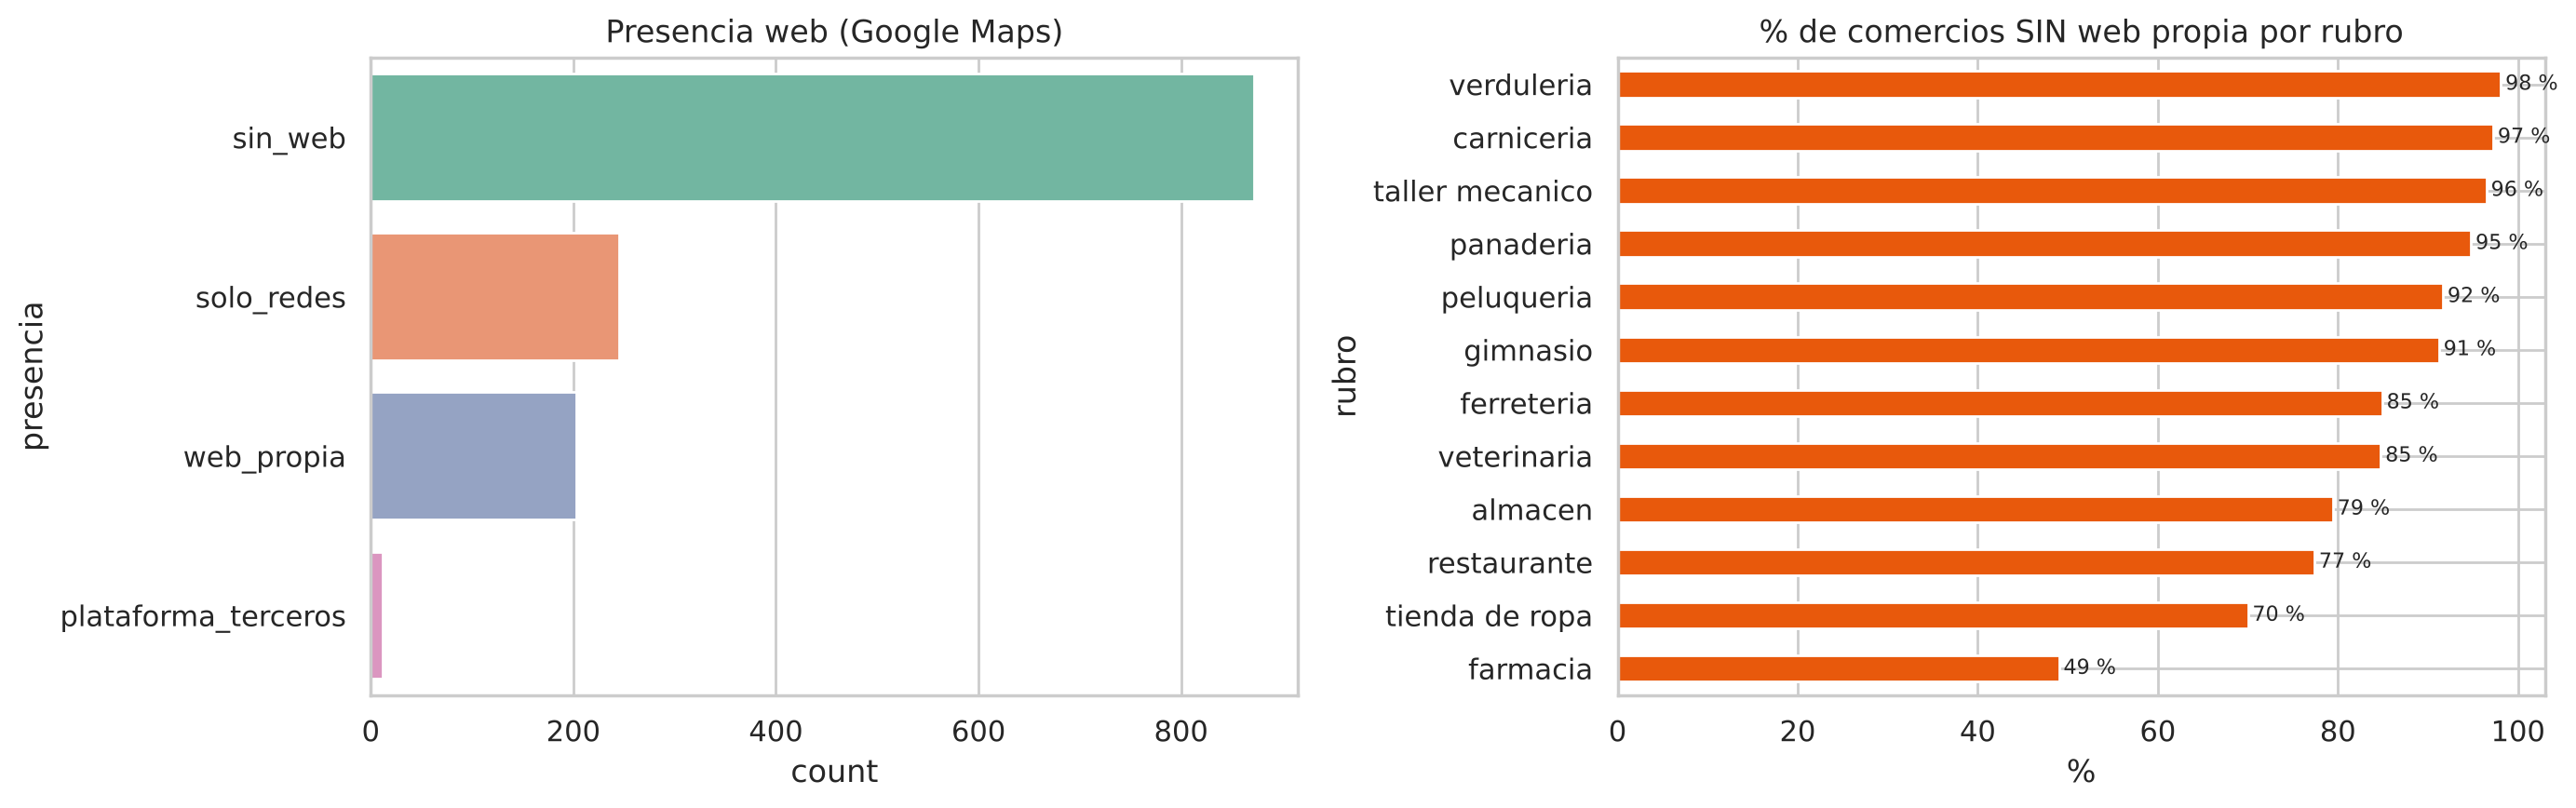

Sin web propia: 84.8 % de 1,332 comercios


presencia,plataforma_terceros,sin_web,solo_redes,web_propia
ciudad,,,,
concordia,1.1,67.7,16.7,14.4
parana,0.7,63.5,19.9,15.9


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
orden = limpio["presencia"].value_counts().index
sns.countplot(data=limpio, y="presencia", order=orden, ax=axes[0], palette="Set2")
axes[0].set_title("Presencia web (Google Maps)")
pct = (1 - limpio.groupby("rubro")["tiene_web_propia"].mean()).sort_values() * 100
pct.plot.barh(ax=axes[1], color="#E8590C")
axes[1].set_title("% de comercios SIN web propia por rubro"); axes[1].set_xlabel("%")
for i, v in enumerate(pct): axes[1].text(v + 0.5, i, f"{v:.0f} %", va="center", fontsize=8)
plt.tight_layout(); plt.show()
print(f"Sin web propia: {100 - limpio['tiene_web_propia'].mean()*100:.1f} % de {len(limpio):,} comercios")
display(pd.crosstab(limpio["ciudad"], limpio["presencia"], normalize="index").round(3) * 100)

### 2.2 Distribuciones

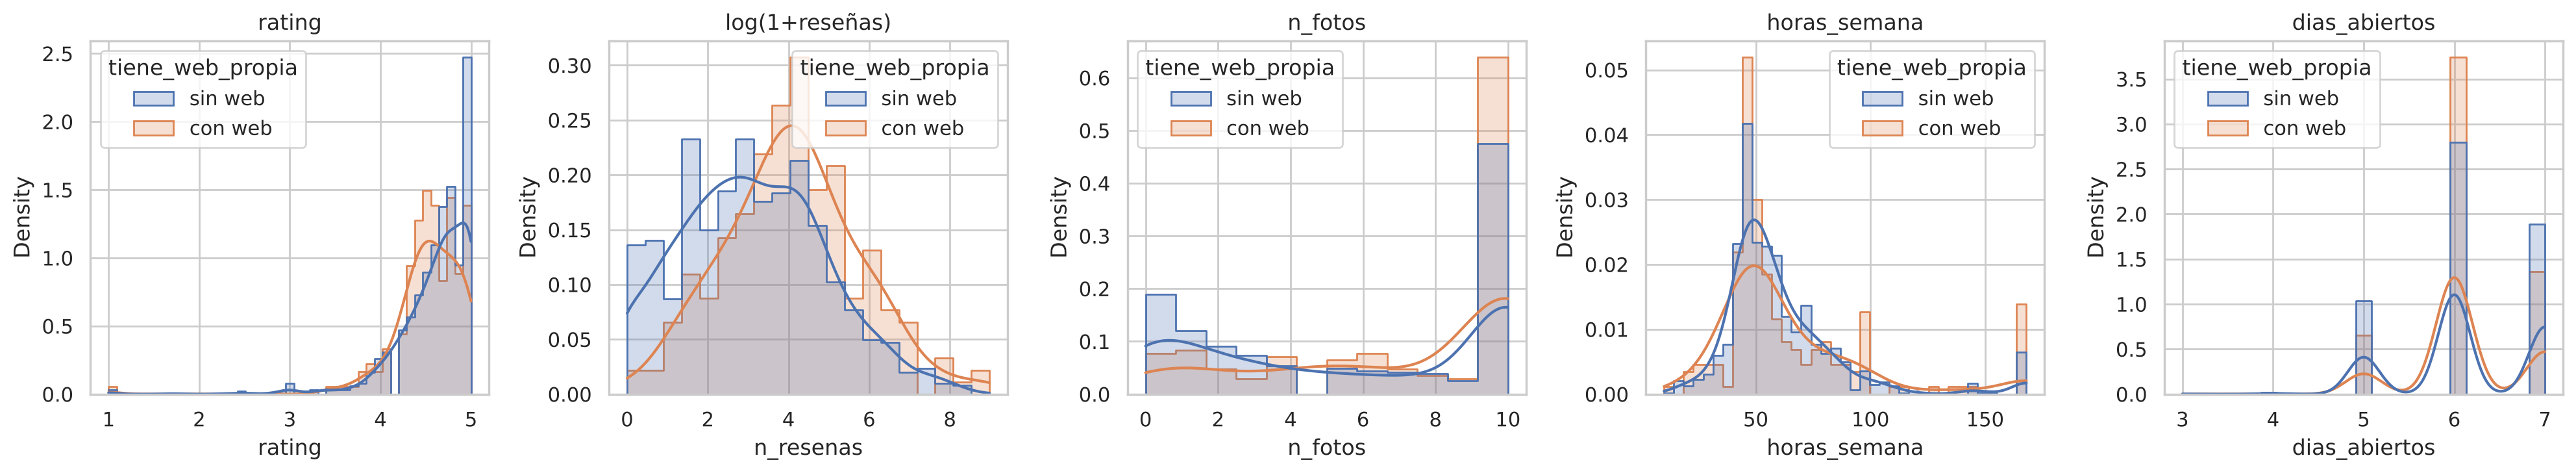

Asimetría: {'rating': -2.99, 'n_resenas': 9.44, 'n_fotos': -0.26, 'horas_semana': 2.18, 'dias_abiertos': -0.3}
n_fotos tiene tope 10 en la respuesta del Actor (la búsqueda 'nearby' devuelve hasta 10 fotos).


In [7]:
num = ["rating", "n_resenas", "n_fotos", "horas_semana", "dias_abiertos"]
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, c in zip(axes, num):
    x = np.log1p(final[c]) if c == "n_resenas" else final[c]
    sns.histplot(x=x, hue=final["tiene_web_propia"].map({0: "sin web", 1: "con web"}), ax=ax, kde=True, element="step", stat="density", common_norm=False)
    ax.set_title(("log(1+reseñas)" if c == "n_resenas" else c))
plt.tight_layout(); plt.show()
print("Asimetría:", final[num].skew().round(2).to_dict())
print("n_fotos tiene tope 10 en la respuesta del Actor (la búsqueda 'nearby' devuelve hasta 10 fotos).")

### 2.3 Correlaciones

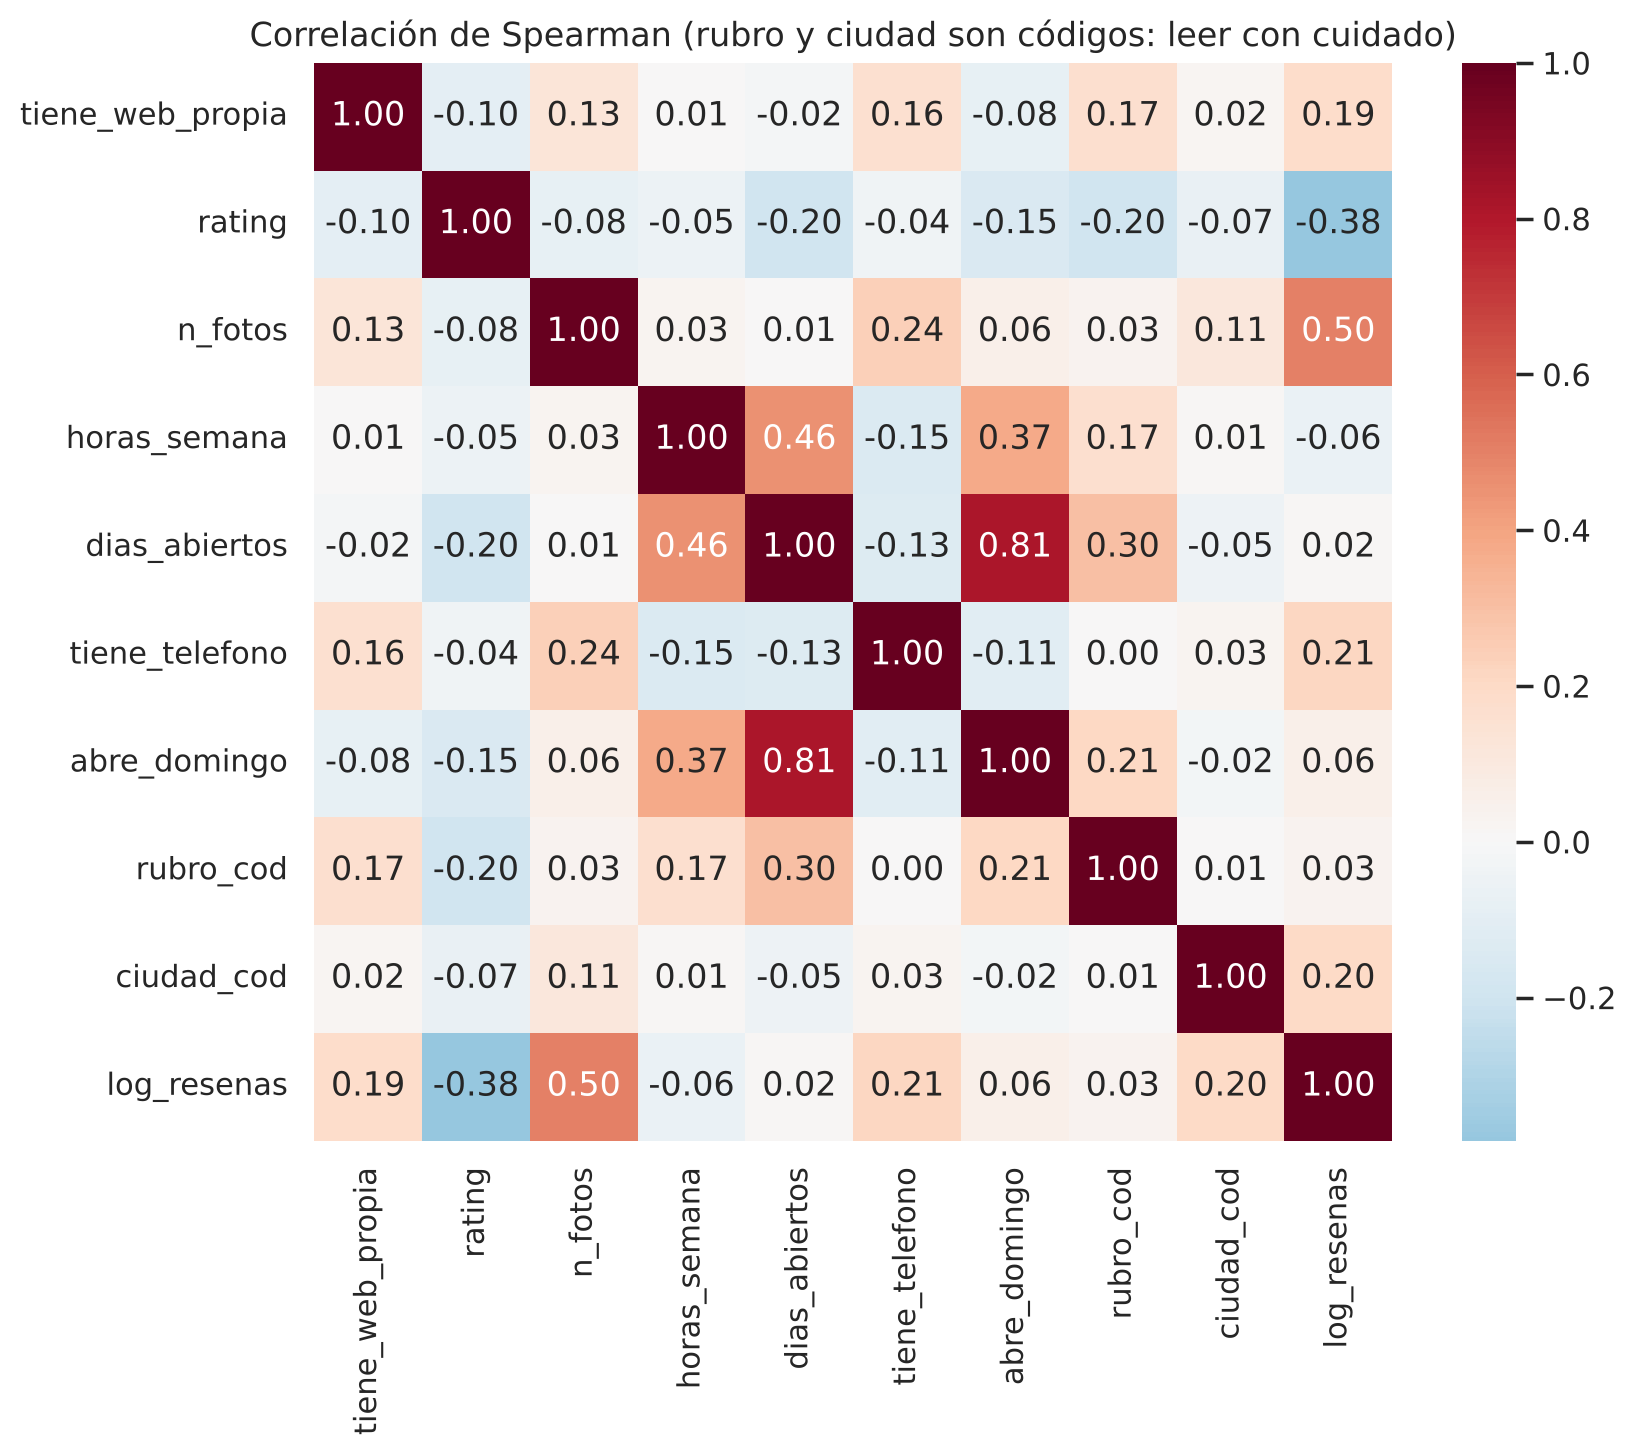

In [8]:
corr = final.assign(log_resenas=np.log1p(final["n_resenas"])).drop(columns=["n_resenas"]).corr(method="spearman")
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)
plt.title("Correlación de Spearman (rubro y ciudad son códigos: leer con cuidado)"); plt.show()

## 3. Inferencia estadística
Siguiendo la guía *ANOVA patitos*: primero la pregunta, después la técnica.

| Pregunta | Variables | Técnica |
|---|---|---|
| ¿La falta de web depende del rubro? | categórica × categórica | Chi-cuadrado + V de Cramér (tamaño del efecto) |
| ¿Y de la ciudad? | categórica × categórica | Chi-cuadrado |
| ¿Los comercios sin web tienen menos movimiento (reseñas)? | numérica × 3+ grupos | ANOVA → supuestos → Plan B (Kruskal-Wallis) + comparaciones con Holm |

In [9]:
def chi2_cramer(tabla):
    chi2, p, gl, _ = stats.chi2_contingency(tabla)
    v = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
    return chi2, p, gl, v
for factor in ["rubro", "ciudad"]:
    t = pd.crosstab(limpio[factor], limpio["tiene_web_propia"])
    chi2, p, gl, v = chi2_cramer(t)
    print(f"Presencia web ~ {factor}: χ² = {chi2:.1f} (gl {gl}) | p = {p:.2e} | V de Cramér = {v:.2f}")
print("Regla práctica V: 0,1 chico · 0,3 mediano · 0,5 grande")

Presencia web ~ rubro: χ² = 185.1 (gl 11) | p = 9.03e-34 | V de Cramér = 0.37
Presencia web ~ ciudad: χ² = 0.5 (gl 1) | p = 4.88e-01 | V de Cramér = 0.02
Regla práctica V: 0,1 chico · 0,3 mediano · 0,5 grande


,sum_sq,df,F,PR(>F)
C(presencia),272.987602,3.0,29.644189,1.496586e-18
Residual,4076.431762,1328.0,NaN,NaN


Supuestos → Shapiro p = 9.33e-04 | Levene p = 9.23e-02
Plan B, Kruskal-Wallis: H = 81.6 | p = 1.37e-17 | ε² = 0.059


,grupo_1,grupo_2,mediana_1,mediana_2,p,p_holm
0,plataforma_terceros,sin_web,21.5,16.0,0.2273,0.6820
1,plataforma_terceros,solo_redes,21.5,44.0,0.8846,0.8846
2,plataforma_terceros,web_propia,21.5,56.0,0.3731,0.7462
3,sin_web,solo_redes,16.0,44.0,0.0000,0.0000
4,sin_web,web_propia,16.0,56.0,0.0000,0.0000
5,solo_redes,web_propia,44.0,56.0,0.0671,0.2682


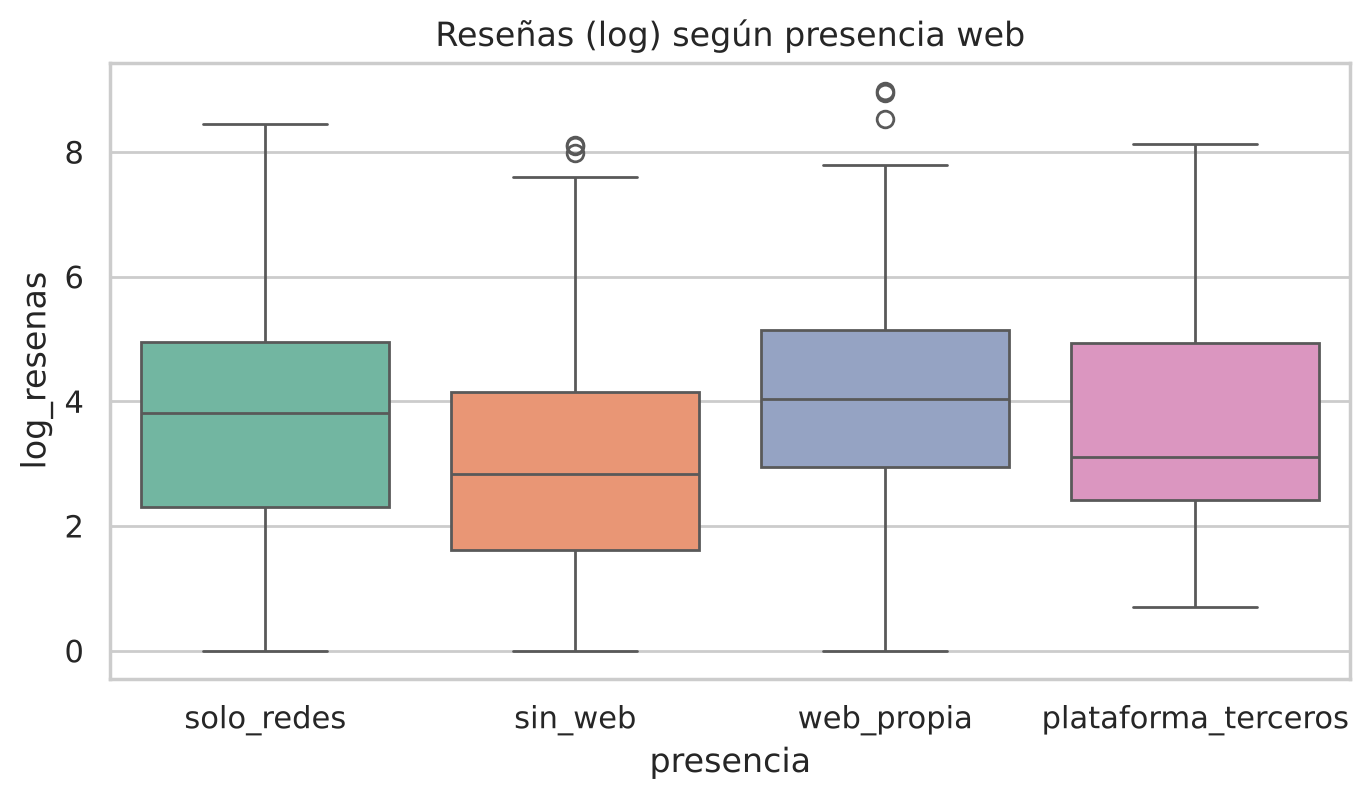

In [10]:
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multitest import multipletests
from itertools import combinations
g = limpio.assign(log_resenas=np.log1p(limpio["n_resenas"]))
modelo = ols("log_resenas ~ C(presencia)", data=g).fit()
display(anova_lm(modelo, typ=2))
sh_p = stats.shapiro(modelo.resid.sample(500, random_state=SEMILLA)).pvalue
lev_p = stats.levene(*[x["log_resenas"] for _, x in g.groupby("presencia")], center="median").pvalue
print(f"Supuestos → Shapiro p = {sh_p:.2e} | Levene p = {lev_p:.2e}")
kw = stats.kruskal(*[x["log_resenas"] for _, x in g.groupby("presencia")])
n, k = len(g), g["presencia"].nunique()
eps2 = (kw.statistic - k + 1) / (n - k)
print(f"Plan B, Kruskal-Wallis: H = {kw.statistic:.1f} | p = {kw.pvalue:.2e} | ε² = {eps2:.3f}")
pares = []
for a, b in combinations(sorted(g["presencia"].unique()), 2):
    pa = stats.mannwhitneyu(g.loc[g.presencia == a, "n_resenas"], g.loc[g.presencia == b, "n_resenas"]).pvalue
    pares.append((a, b, g.loc[g.presencia == a, "n_resenas"].median(), g.loc[g.presencia == b, "n_resenas"].median(), pa))
pares = pd.DataFrame(pares, columns=["grupo_1", "grupo_2", "mediana_1", "mediana_2", "p"])
pares["p_holm"] = multipletests(pares["p"], method="holm")[1]
display(pares.round(4))
plt.figure(figsize=(8, 4)); sns.boxplot(data=g, x="presencia", y="log_resenas", palette="Set2")
plt.title("Reseñas (log) según presencia web"); plt.show()

## 4. Selección de features (máx. 10: hasta 5 lineales + 5 no lineales)
- **Lineales:** correlación punto-biserial con el target y coeficientes de una regresión logística estandarizada.
- **No lineales:** información mutua y la importancia por permutación de un Random Forest.

In [11]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, train_test_split

X = final.drop(columns=["tiene_web_propia"]).assign(n_resenas=lambda d: np.log1p(d["n_resenas"]))
X = pd.get_dummies(X.astype({"rubro_cod": int, "ciudad_cod": int}), columns=["rubro_cod", "ciudad_cod"], drop_first=True, dtype=float)
y = final["tiene_web_propia"].astype(int)
base = ["rating", "n_resenas", "n_fotos", "horas_semana", "dias_abiertos", "tiene_telefono", "abre_domingo"]
pb = {c: stats.pointbiserialr(y, X[c])[0] for c in base}
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")).fit(X[base], y)
coef = dict(zip(base, logit[-1].coef_[0]))
mi = dict(zip(X.columns, mutual_info_classif(X, y, random_state=SEMILLA)))
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEMILLA)
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=SEMILLA).fit(Xtr, ytr)
pi = permutation_importance(rf, Xte, yte, scoring="roc_auc", n_repeats=10, random_state=SEMILLA)
imp = dict(zip(X.columns, pi.importances_mean))
sel = pd.DataFrame({"r_puntobiserial": pd.Series(pb), "coef_logit_std": pd.Series(coef),
                    "info_mutua": pd.Series(mi), "importancia_RF": pd.Series(imp)}).round(3)
display(sel.sort_values("importancia_RF", ascending=False).head(15))

,r_puntobiserial,coef_logit_std,info_mutua,importancia_RF
rubro_cod_12,NaN,NaN,0.035,0.048
tiene_telefono,0.158,0.604,0.014,0.032
n_resenas,0.191,0.581,0.014,0.029
rubro_cod_10,NaN,NaN,0.009,0.025
rubro_cod_5,NaN,NaN,0.009,0.010
n_fotos,0.131,0.139,0.013,0.010
rubro_cod_11,NaN,NaN,0.011,0.009
rubro_cod_8,NaN,NaN,0.003,0.009
rubro_cod_3,NaN,NaN,0.005,0.007
ciudad_cod_2,NaN,NaN,0.000,0.004


In [12]:
lineales = pd.Series(pb).abs().sort_values(ascending=False).head(5).index.tolist()
no_lineales = (pd.Series(imp).groupby(lambda c: c.split("_")[0] + "_cod" if c.startswith(("rubro", "ciudad")) else c).sum()
               .sort_values(ascending=False).drop(lineales, errors="ignore").head(5).index.tolist())
print("5 features lineales   :", lineales)
print("Features no lineales  :", no_lineales)
print(f"Total: {len(lineales) + len(no_lineales)} features (las 9 disponibles; rubro y ciudad entran como variables dummy)")

5 features lineales   : ['n_resenas', 'tiene_telefono', 'n_fotos', 'abre_domingo', 'horas_semana']
Features no lineales  : ['rubro_cod', 'ciudad_cod', 'dias_abiertos', 'rating']
Total: 9 features (las 9 disponibles; rubro y ciudad entran como variables dummy)


## 5. Modelo: ¿qué comercios *deberían* tener web y no la tienen?
Target: `tiene_web_propia` (15 % de positivos → clases desbalanceadas, se usa `class_weight="balanced"`).
Se compara contra una **línea base** (regla trivial) con validación cruzada estratificada de 5 particiones.

**Uso de negocio:** el modelo aprende el perfil de los comercios que *sí* tienen web. Entre los que **no** la tienen, los que tienen probabilidad alta se parecen a los que ya invirtieron en una → son los leads con más chances de comprar.

In [13]:
from sklearn.dummy import DummyClassifier
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
modelos = {
    "Línea base (estratificada)": DummyClassifier(strategy="stratified", random_state=SEMILLA),
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=SEMILLA),
}
res = {n: cross_validate(m, X, y, cv=cv, scoring=["roc_auc", "f1", "recall", "precision"]) for n, m in modelos.items()}
tabla = pd.DataFrame({n: {k.replace("test_", ""): v.mean() for k, v in r.items() if k.startswith("test_")} for n, r in res.items()}).T.round(3)
display(tabla)
mejor = tabla["roc_auc"].idxmax(); print("Mejor modelo por ROC-AUC:", mejor)

,roc_auc,f1,recall,precision
Línea base (estratificada),0.506,0.171,0.182,0.161
Regresión logística,0.801,0.433,0.719,0.310
Random Forest,0.785,0.430,0.596,0.337


Mejor modelo por ROC-AUC: Regresión logística


,rating,n_resenas,lead_caliente
,mean,mean,mean
prioridad,,,
baja,4.58,24.45,0.22
media,4.64,78.95,0.53
alta,4.57,244.86,0.77


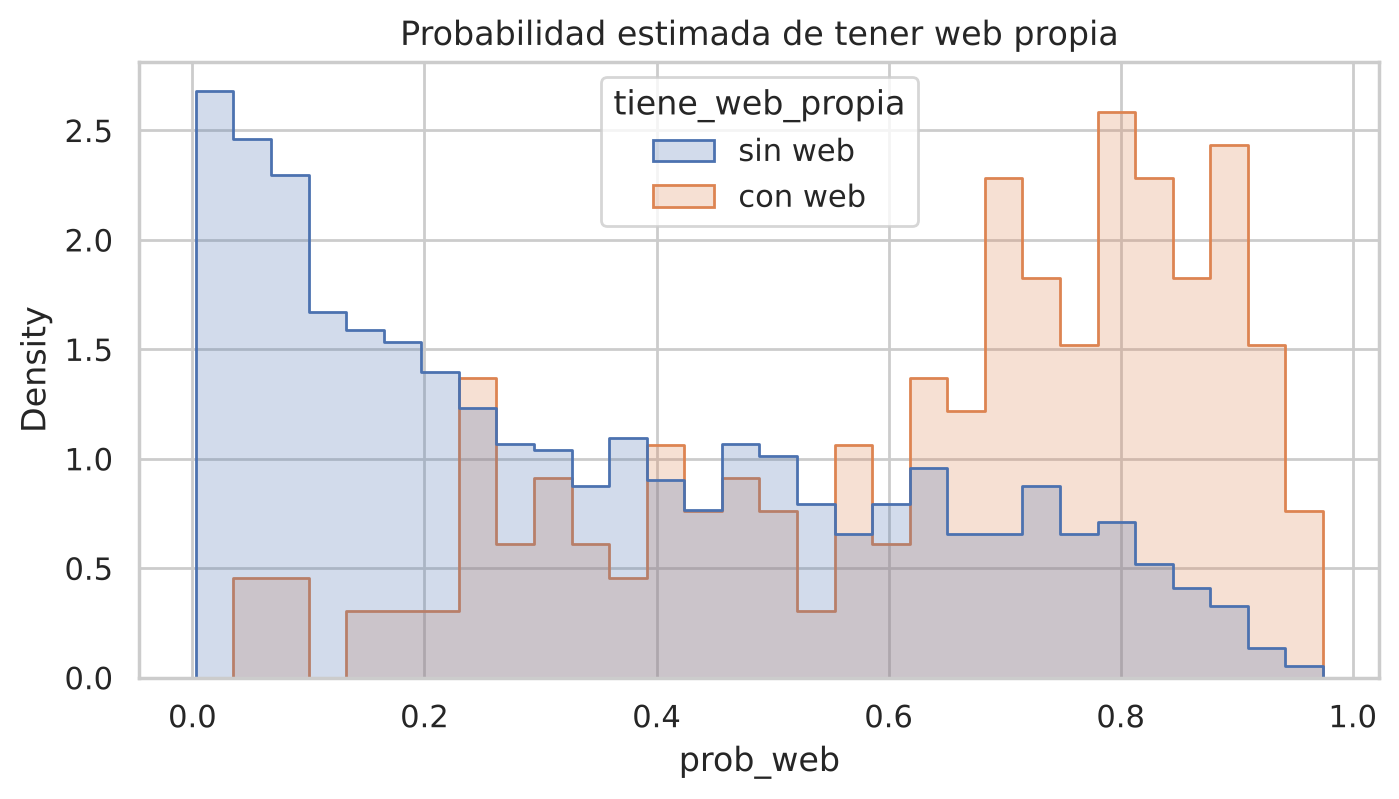

In [14]:
proba = cross_val_predict(modelos[mejor], X, y, cv=cv, method="predict_proba")[:, 1]
limpio["prob_web"] = proba
leads_ = limpio[limpio["es_lead"] == 1].copy()
leads_["prioridad"] = pd.qcut(leads_["prob_web"], 3, labels=["baja", "media", "alta"])
display(leads_.groupby("prioridad")[["rating", "n_resenas", "lead_caliente"]].agg(["mean"]).round(2))
plt.figure(figsize=(8, 4))
sns.histplot(data=limpio, x="prob_web", hue=limpio["tiene_web_propia"].map({0: "sin web", 1: "con web"}), bins=30, element="step", stat="density", common_norm=False)
plt.title("Probabilidad estimada de tener web propia"); plt.show()

## 6. Métrica de negocio y KPI
- **Métrica de negocio:** % de comercios sin web propia por rubro y ciudad (= tamaño del mercado al que se le puede vender una web).
- **KPI:** leads calientes por corrida y **costo por lead** (costo de Apify / leads calientes).
- **Proyección** (supuestos marcados, a validar con la cliente): tasa de respuesta al mail y precio de una web básica.

In [15]:
COSTO_CORRIDA_USD = 0.12        # 2 corridas de kaix/google-maps-places-scraper (1.415 lugares a US$ 0,08/1.000 + cómputo). Fuente: consola Apify, 24/11/2026
TASA_CONVERSION = 0.03          # SUPUESTO: 3 % de los leads contactados compra una web
PRECIO_WEB_ARS = 250_000        # SUPUESTO: precio de una web básica para comercio
n_leads, n_cal = int(limpio["es_lead"].sum()), int(limpio["lead_caliente"].sum())
kpi = pd.Series({
    "comercios analizados": len(limpio),
    "% sin web propia": round(100 * (1 - limpio["tiene_web_propia"].mean()), 1),
    "leads (sin web propia)": n_leads,
    "leads calientes": n_cal,
    "costo por lead caliente (USD)": round(COSTO_CORRIDA_USD / n_cal, 5),
    "ventas esperadas (leads calientes × conversión)": round(n_cal * TASA_CONVERSION, 1),
    "facturación esperada (ARS)": round(n_cal * TASA_CONVERSION * PRECIO_WEB_ARS),
})
display(kpi.map(lambda v: f"{v:,.5g}" if isinstance(v, float) else f"{v:,}").to_frame("valor"))

,valor
comercios analizados,"1,332"
% sin web propia,84.8
leads (sin web propia),"1,129"
leads calientes,574
costo por lead caliente (USD),0.00021
ventas esperadas (leads calientes × conversión),17.2
facturación esperada (ARS),4.305e+06


## 7. Exportar

In [16]:
os.makedirs(DIR_SALIDA, exist_ok=True)
final.to_csv(os.path.join(DIR_SALIDA, "tabla_final.csv"), index=False)
limpio.drop(columns=["horarios"]).to_csv(os.path.join(DIR_SALIDA, "comercios_limpios.csv"), index=False)
leads(limpio).merge(limpio[["nombre", "direccion", "prob_web"]], on=["nombre", "direccion"], how="left") \
    .sort_values(["lead_caliente", "prob_web"], ascending=False).to_csv(os.path.join(DIR_SALIDA, "leads.csv"), index=False)
descartes.drop(columns=["horarios"], errors="ignore").to_csv(os.path.join(DIR_SALIDA, "auditoria_descartes.csv"), index=False)
print("Archivos en", DIR_SALIDA, "→", sorted(os.listdir(DIR_SALIDA)))

Archivos en ../../data/processed → ['auditoria_descartes.csv', 'comercios_limpios.csv', 'leads.csv', 'tabla_final.csv']
